> **Generated** from [`coin_toss_notebook.py`](../coin_toss_notebook.py) by `scripts/build_ipynb.py`: don't edit this file.

In [ ]:
# cell: client
# Shared scaffolding, generated from client.py by scripts/sync_client.py: edit client.py, not this block.
# Only the public helpers are visible to other cells; import any module you use in your own cells.
# Imported under private names so a notebook's setup cell exposes only the public helpers (and the module
# names stay free for the notebook's own imports, as they would be with `from moth_atlas import ...`).
import hashlib as _hashlib
import mimetypes as _mimetypes
import os as _os
import time as _time
from pathlib import Path as _Path

import requests as _requests


_session = _requests.Session()
_session.headers["User-Agent"] = "atlas-engine-notebooks"


def _call(method, path, **kw):
    # Env is read per call, so a key exported after import still takes effect.
    base = _os.environ.get("MOTH_API_BASE", "https://api.mothquantum.com").rstrip("/")
    key = _os.environ.get("MOTH_API_KEY", "")
    if not key:
        raise RuntimeError("MOTH_API_KEY is not set: create a key on the Atlas API keys page and export it")
    r = _session.request(method, f"{base}/api/v1{path}", headers={"Authorization": f"Bearer {key}"}, timeout=30, **kw)
    if r.status_code >= 400:  # keep the API's error body; raise_for_status() would drop it
        raise RuntimeError(f"{method} {path} -> {r.status_code}: {r.text[:300]}")
    return r.json() if r.content else None


def _presigned(method, url, **kw):
    # Presigned URLs carry their own signature: never send the API key to them (plain requests, not _session).
    r = _requests.request(method, url, timeout=60, **kw)
    if r.status_code >= 400:
        raise RuntimeError(f"{method} presigned URL -> {r.status_code}: {r.text[:300]}")
    return r


_uploaded = {}  # (sha256, content_type) -> asset_id, so re-running a cell doesn't re-upload


def upload(file: str | _os.PathLike | bytes, content_type: str | None = None, filename: str | None = None) -> str:
    """Upload a file path or raw bytes; returns its asset id.

    content_type defaults to a guess from the filename; filename names uploaded bytes.
    Runs the three API steps: create, PUT to the presigned URL, complete."""
    if isinstance(file, (bytes, bytearray)):
        data, filename = bytes(file), filename or "file"
    else:
        data, filename = _Path(file).read_bytes(), filename or _Path(file).name
    content_type = content_type or _mimetypes.guess_type(filename)[0] or "application/octet-stream"
    key = (_hashlib.sha256(data).hexdigest(), content_type)
    if key not in _uploaded:
        asset = _call("POST", "/assets", json={"filename": filename, "content_type": content_type, "size_bytes": len(data)})
        up = asset["upload"]
        _presigned(up.get("method", "PUT"), up["url"], data=data, headers=up["headers"])
        _uploaded[key] = _call("POST", f"/assets/{asset['asset_id']}/complete")["asset_id"]
    return _uploaded[key]


def submit(engine: str, params: dict, input_files: dict[str, str] | None = None) -> str:
    """Start a job on an engine; returns its job id. params is a dict of the engine's parameters; input_files is a dict mapping each input slot name to an asset id."""
    body = {"params": params, **({"input_files": input_files} if input_files else {})}
    return _call("POST", f"/engines/{engine}/process", json=body)["job_id"]


def wait(job_id: str, interval: float = 1.5, timeout: float = 600, on_update=None) -> None:
    """Block until the job completes, checking every interval seconds; raises if it fails, is cancelled, or takes longer than timeout seconds.

    on_update(job) is called whenever the status changes, with the status response as a dict,
    e.g. on_update=lambda job: print(job["status"])."""
    deadline, last = _time.monotonic() + timeout, None
    while _time.monotonic() < deadline:
        job = _call("GET", f"/jobs/{job_id}/status")
        if on_update and job["status"] != last:
            on_update(job)
            last = job["status"]
        if job["status"] == "completed":
            return
        if job["status"] in ("failed", "cancelled"):
            raise RuntimeError(f"Job {job_id} {job['status']}: {job.get('error')}")
        _time.sleep(interval)
    raise TimeoutError(f"Job {job_id} did not finish in {timeout}s")


def download(job_id: str, slot: str = "result") -> bytes | dict:
    """Return a finished job's output: the bytes of the file in slot (or the first output), or the inline JSON result (a dict) for engines that produce no file."""
    res = _call("GET", f"/jobs/{job_id}/result")
    outputs = res.get("outputs") or []
    out = next((o for o in outputs if o.get("slot") == slot), outputs[0] if outputs else None)
    if out is None:
        if res.get("result") is None:
            raise RuntimeError(f"Job {job_id} finished without an output")
        return res["result"]
    url = out.get("url") or _call("GET", f"/assets/{out['output_asset_id']}/download")["download_url"]
    return _presigned("GET", url).content

In [ ]:
# cell: setup
# Import every module your cells use here; the hidden block at the top provides only the API helpers.
import marimo as mo

Flip a quantum coin a number of times and get back the heads and tails counts.

## Try it

Set the parameters, then press **Run**.

In [ ]:
# cell: engine
# upload, submit, wait and download: the Moth API helpers, from the hidden block at the top.
ENGINE_ID = "coin-toss-v1"

def run_engine(params):
    """Run one job; returns its JSON result as a dict."""
    job_id = submit(ENGINE_ID, params)
    wait(job_id)
    return download(job_id)

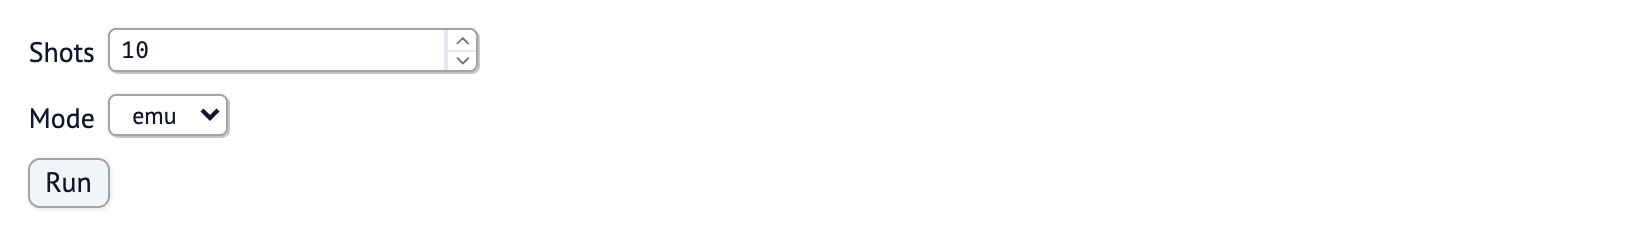

In [ ]:
# cell: params
# Keys are the engine's parameter names, so params.value is the dict sent to the API.
params = mo.ui.dictionary({
    "shots": mo.ui.number(1, value=10, label="Shots"),
    "mode": mo.ui.dropdown(["emu", "qpu"], value="emu", label="Mode"),
})
run = mo.ui.run_button(label="Run")
mo.vstack([params.vstack(), run])

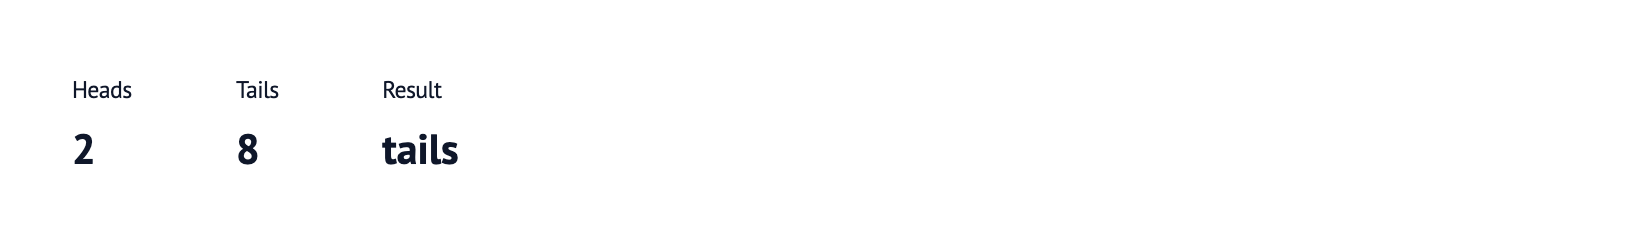

In [ ]:
# cell: run
mo.stop(not run.value, mo.md("Press **Run** to see the result."))
result = run_engine(params.value)
mo.hstack([
    mo.stat(result["heads"], label="Heads"),
    mo.stat(result["tails"], label="Tails"),
    mo.stat(result["output"], label="Result"),
], justify="start")

## Parameters

| name | type | default | what it does |
|---|---|---|---|
| `shots` | integer, above 0 | 10 | Number of coin tosses to run. More shots bring the heads/tails split closer to 50/50. |
| `mode` | `emu` or `qpu` | `emu` | `emu` uses the platform's simulator and returns in seconds; `qpu` submits to real IBM Quantum hardware and can queue for minutes. |
| `backend_name` | string | none | IBM Quantum backend to run on when mode is `qpu`. Leave blank to let the platform choose the least busy one. |

**Returns:** `heads` and `tails` (counts), `shots` (the number of measurements taken) and `output` (whichever had more counts).

## How it works

A single qubit is put into equal superposition with a Hadamard gate and measured `shots` times. The outcomes are counted and the majority is reported as the result.

## Experiments

Each experiment changes one parameter and keeps the others fixed. Press its button to run it.

### Shots

More shots bring the heads/tails split closer to 50/50.

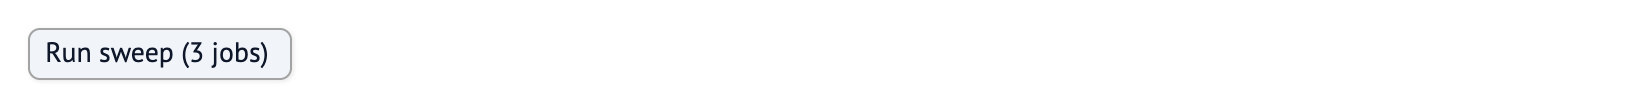

In [ ]:
# cell: sweep-params
# Edit the values, then press the button: one job per value.
SWEEP = (10, 100, 1000)
run_sweep = mo.ui.run_button(label=f"Run sweep ({len(SWEEP)} jobs)")
run_sweep

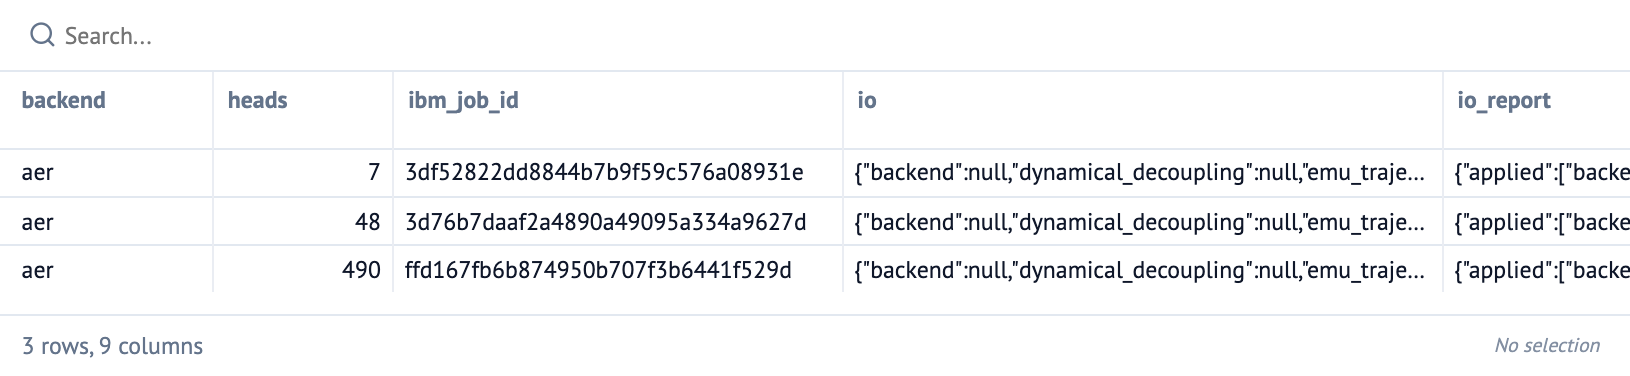

In [ ]:
# cell: sweep
mo.stop(not run_sweep.value, mo.md("Press **Run sweep** to compare the values above."))
rows = [run_engine({**params.value, "shots": v}) for v in SWEEP]
mo.ui.table(rows, selection=None)

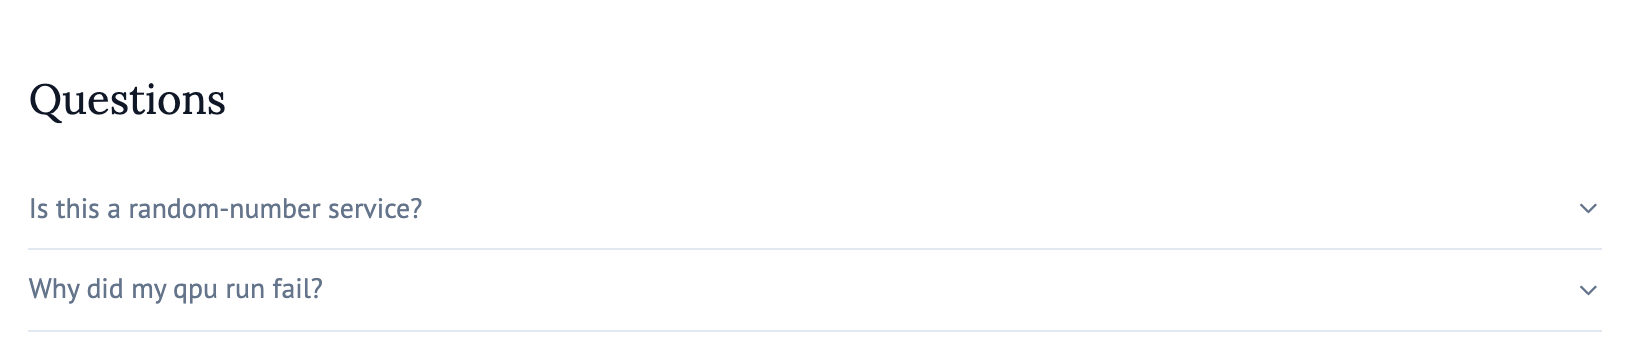

In [ ]:
# cell: questions
mo.vstack([mo.md("## Questions"), mo.accordion({
    "Is this a random-number service?": "No. The circuit is one qubit; results are a probability sample, not a random-number service with guarantees.",
    "Why did my qpu run fail?": "A run still going after 300 s is cancelled and the job ends failed. Device queue times can be minutes to hours.",
})])